# SnowDRIP at a glacier, forced by ERA5

The mass-balance profile, refreezing and firn temperature of one glacier, from the ERA5 climatologies
([doi:10.5281/zenodo.24079220](https://doi.org/10.5281/zenodo.24079220)). This is the forcing the SnowDRIP melt
coefficients were calibrated with: temperature moved with 6.5 K/km, precipitation times 1.70,
and shortwave radiation moved to each elevation (`era5_forcing.py`).

The record is read from `data/era5_climatology/`, or from the folder set in `data/folders.local.toml`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import snowdrip as sd
from era5_forcing import ERA5Forcing, data_folder

DATA = data_folder("era5_climatology")

Storbreen, southern Norway (WGMS id 302).

In [2]:
lat, lon = 61.57, 8.13
forcing = ERA5Forcing(DATA, lat, lon)
print(f"ERA5 surface at this grid cell: {forcing.z_ref:.0f} m")

ERA5 surface at this grid cell: 1365 m


Run the model at each elevation of the profile.

In [3]:
z = np.arange(1000.0, 2601.0, 50.0)
rows = []
for zi in z:
    y = forcing(zi)
    r = sd.run(y["T_m"], y["P_m"], y["SW_m"])
    rows.append((r["S"] + r["R"], r["M"], r["W"], r["bdot"], r["T10m"]))
P, M, W, bdot, T10m = np.array(rows).T

y = forcing(forcing.z_ref)
z_ela = sd.ela_elevation(y["T_m"], forcing.z_ref, forcing.gamma, y["P_m"], forcing.shortwave)
print(f"ELA: {z_ela:.0f} m")

ELA: 2140 m


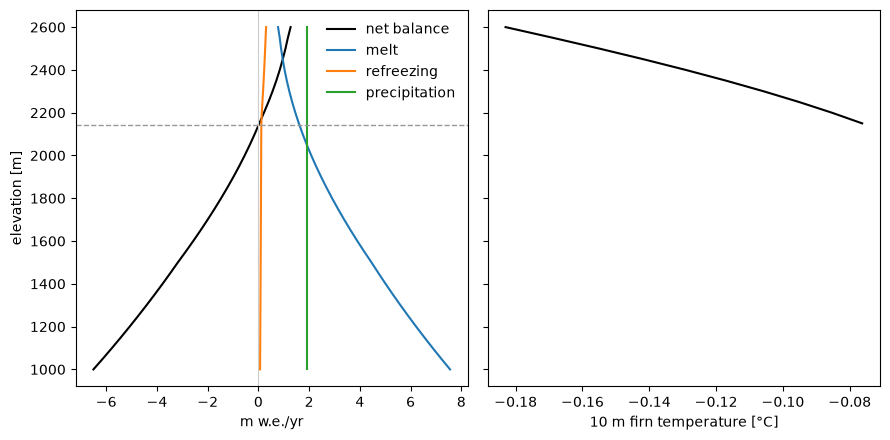

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 4.5), sharey=True)
a.plot(bdot, z, "k", label="net balance")
a.plot(M, z, label="melt")
a.plot(W, z, label="refreezing")
a.plot(P, z, label="precipitation")
a.axhline(z_ela, color="0.6", ls="--", lw=1)
a.axvline(0, color="0.8", lw=0.8)
a.set(xlabel="m w.e./yr", ylabel="elevation [m]")
a.legend(frameon=False)
b.plot(T10m, z, "k")
b.set(xlabel="10 m firn temperature [°C]")
fig.tight_layout()